In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

In [2]:
data_path = Path("../data/raw/manufacturing_data.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (10000, 16)


,Machine_ID,Timestamp,Machine_Type,Machine_Age_Years,Operating_Hours,Temperature_C,Vibration_mm_s,Pressure_bar,Motor_Current_A,Production_Count,Production_Rate,Last_Maintenance_Days,Maintenance_Count,Failure_Count,Failure_Next_30_Days,Failure_Type
0,M052,2025-01-01 00:00:00,Grinding,15,33059,86.051980,6.004030,7.802045,24.804402,1724,86.300701,216,6,1,1,Bearing Failure
1,M093,2025-01-01 01:00:00,Grinding,14,10822,77.952672,2.257927,5.844986,19.914570,1498,83.440343,310,4,2,0,No Failure
2,M015,2025-01-01 02:00:00,CNC,10,7210,82.249814,2.947153,7.627787,23.277713,1238,82.008945,294,5,0,0,No Failure
3,M072,2025-01-01 03:00:00,Milling,13,31862,60.092865,4.951945,6.324292,15.726880,1117,92.229930,9,13,1,0,No Failure
4,M061,2025-01-01 04:00:00,Lathe,6,32880,58.508011,5.405021,6.955872,12.816718,485,84.045439,230,18,1,0,No Failure


In [3]:
features = [
    "Machine_Type",
    "Machine_Age_Years",
    "Operating_Hours",
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar",
    "Motor_Current_A",
    "Production_Count",
    "Production_Rate",
    "Last_Maintenance_Days",
    "Maintenance_Count",
    "Failure_Count"
]

target = "Failure_Next_30_Days"

X = df[features]
y = df[target]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (10000, 12)
Target: (10000,)


Identify categorical and numerical features

In [4]:
categorical_features = [
    "Machine_Type"
]

numerical_features = [
    "Machine_Age_Years",
    "Operating_Hours",
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar",
    "Motor_Current_A",
    "Production_Count",
    "Production_Rate",
    "Last_Maintenance_Days",
    "Maintenance_Count",
    "Failure_Count"
]

Train/test split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (8000, 12)
Testing : (2000, 12)


Build the preprocessing pipeline

In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

Build our first ML model

In [7]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

Create the complete pipeline

In [8]:
pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", model)
    ]
)

In [9]:
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different 

Make predictions

In [10]:
y_pred = pipeline.predict(X_test)

y_probability = pipeline.predict_proba(X_test)[:, 1]

Evaluate

In [11]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.98      0.88      1573
           1       0.61      0.13      0.21       427

    accuracy                           0.80      2000
   macro avg       0.71      0.55      0.55      2000
weighted avg       0.76      0.80      0.74      2000



In [12]:
print("ROC-AUC:", roc_auc_score(y_test, y_probability))

ROC-AUC: 0.7221169292704315


In [13]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Confusion Matrix:
[[1539   34]
 [ 373   54]]


In [14]:
numeric_features = [
    "Machine_Age_Years",
    "Operating_Hours",
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar",
    "Motor_Current_A",
    "Production_Count",
    "Production_Rate",
    "Last_Maintenance_Days",
    "Maintenance_Count",
    "Failure_Count"
]

correlation = df[numeric_features + ["Failure_Next_30_Days"]].corr()

correlation["Failure_Next_30_Days"].sort_values(ascending=False)

Failure_Next_30_Days     1.000000
Last_Maintenance_Days    0.200444
Operating_Hours          0.199255
Machine_Age_Years        0.117951
Vibration_mm_s           0.106644
Temperature_C            0.100149
Failure_Count            0.068540
Motor_Current_A          0.009593
Production_Count        -0.001005
Production_Rate         -0.008026
Maintenance_Count       -0.008153
Pressure_bar            -0.012331
Name: Failure_Next_30_Days, dtype: float64

check the actual failure probabilities

In [15]:
df.groupby("Failure_Next_30_Days")[numeric_features].mean().T

Failure_Next_30_Days,0,1
Machine_Age_Years,7.712196,8.960693
Operating_Hours,23478.885540,30464.002340
Temperature_C,69.426869,71.843446
Vibration_mm_s,3.910782,4.297894
Pressure_bar,6.010899,5.980787
Motor_Current_A,19.989894,20.084570
Production_Count,1042.018441,1040.662611
Production_Rate,84.988873,84.795352
Last_Maintenance_Days,172.220527,223.495555
Maintenance_Count,9.499555,9.385119


check probability separation

In [16]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Probability": y_probability
})

print(
    results.groupby("Actual")["Probability"].describe()
)

         count      mean       std    min     25%    50%    75%   max
Actual                                                               
0       1573.0  0.187076  0.111805  0.025  0.1100  0.160  0.230  0.77
1        427.0  0.300995  0.164146  0.040  0.1725  0.265  0.395  0.89


In [27]:
print(
    results.sort_values(
        "Probability",
        ascending=False
    ).head(20)
)

      Actual  Probability
1905       1        0.890
384        0        0.770
789        1        0.765
202        1        0.735
1750       1        0.725
489        1        0.710
1897       1        0.700
727        1        0.695
759        1        0.695
1112       0        0.690
1324       1        0.685
1518       1        0.680
1719       1        0.665
1232       1        0.660
1915       1        0.660
742        1        0.655
638        0        0.655
451        1        0.655
583        0        0.655
808        1        0.650


In [17]:
numeric_features = [
    "Machine_Age_Years",
    "Operating_Hours",
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar",
    "Motor_Current_A",
    "Production_Count",
    "Production_Rate",
    "Last_Maintenance_Days",
    "Maintenance_Count",
    "Failure_Count"
]

correlation = (
    df[numeric_features + ["Failure_Next_30_Days"]]
    .corr()["Failure_Next_30_Days"]
    .sort_values(ascending=False)
)

correlation

Failure_Next_30_Days     1.000000
Last_Maintenance_Days    0.200444
Operating_Hours          0.199255
Machine_Age_Years        0.117951
Vibration_mm_s           0.106644
Temperature_C            0.100149
Failure_Count            0.068540
Motor_Current_A          0.009593
Production_Count        -0.001005
Production_Rate         -0.008026
Maintenance_Count       -0.008153
Pressure_bar            -0.012331
Name: Failure_Next_30_Days, dtype: float64

In [18]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

In [19]:
pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)

y_probability = pipeline.predict_proba(X_test)[:, 1]

In [20]:
print(classification_report(y_test, y_pred))

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        y_probability
    )
)

print(
    "Confusion Matrix:"
)

print(
    confusion_matrix(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.80      0.98      0.88      1573
           1       0.61      0.13      0.21       427

    accuracy                           0.80      2000
   macro avg       0.71      0.55      0.55      2000
weighted avg       0.76      0.80      0.74      2000

ROC-AUC: 0.7221169292704315
Confusion Matrix:
[[1539   34]
 [ 373   54]]


In [21]:
print("Dataset shape:", df.shape)

print("\nTarget distribution:")
print(df["Failure_Next_30_Days"].value_counts())

print("\nTarget percentage:")
print(
    df["Failure_Next_30_Days"]
    .value_counts(normalize=True) * 100
)

Dataset shape: (10000, 16)

Target distribution:
Failure_Next_30_Days
0    7863
1    2137
Name: count, dtype: int64

Target percentage:
Failure_Next_30_Days
0    78.63
1    21.37
Name: proportion, dtype: float64


Check the new correlation

In [22]:
numeric_features = [
    "Machine_Age_Years",
    "Operating_Hours",
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar",
    "Motor_Current_A",
    "Production_Count",
    "Production_Rate",
    "Last_Maintenance_Days",
    "Maintenance_Count",
    "Failure_Count"
]

correlation = (
    df[numeric_features + ["Failure_Next_30_Days"]]
    .corr()["Failure_Next_30_Days"]
    .sort_values(ascending=False)
)

correlation

Failure_Next_30_Days     1.000000
Last_Maintenance_Days    0.200444
Operating_Hours          0.199255
Machine_Age_Years        0.117951
Vibration_mm_s           0.106644
Temperature_C            0.100149
Failure_Count            0.068540
Motor_Current_A          0.009593
Production_Count        -0.001005
Production_Rate         -0.008026
Maintenance_Count       -0.008153
Pressure_bar            -0.012331
Name: Failure_Next_30_Days, dtype: float64

Run the Random Forest again

In [23]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

In [24]:
pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)

y_probability = pipeline.predict_proba(X_test)[:, 1]

In [25]:
print(classification_report(y_test, y_pred))

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_probability)
)

print("Confusion Matrix:")

print(
    confusion_matrix(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.80      0.98      0.88      1573
           1       0.61      0.13      0.21       427

    accuracy                           0.80      2000
   macro avg       0.71      0.55      0.55      2000
weighted avg       0.76      0.80      0.74      2000

ROC-AUC: 0.7221169292704315
Confusion Matrix:
[[1539   34]
 [ 373   54]]


In [26]:
print(classification_report(y_test, y_pred))

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_probability)
)

print("Confusion Matrix:")

print(
    confusion_matrix(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.80      0.98      0.88      1573
           1       0.61      0.13      0.21       427

    accuracy                           0.80      2000
   macro avg       0.71      0.55      0.55      2000
weighted avg       0.76      0.80      0.74      2000

ROC-AUC: 0.7221169292704315
Confusion Matrix:
[[1539   34]
 [ 373   54]]


In [28]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.50, 0.40, 0.30, 0.25, 0.20, 0.15]

for threshold in thresholds:

    predictions = (
        y_probability >= threshold
    ).astype(int)

    precision = precision_score(
        y_test,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        zero_division=0
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

Threshold: 0.50 | Precision: 0.620 | Recall: 0.133 | F1: 0.220
Threshold: 0.40 | Precision: 0.522 | Recall: 0.246 | F1: 0.334
Threshold: 0.30 | Precision: 0.439 | Recall: 0.436 | F1: 0.437
Threshold: 0.25 | Precision: 0.403 | Recall: 0.543 | F1: 0.463
Threshold: 0.20 | Precision: 0.352 | Recall: 0.686 | F1: 0.465
Threshold: 0.15 | Precision: 0.289 | Recall: 0.806 | F1: 0.425


Create the risk classification

In [29]:
def classify_risk(probability):
    if probability >= 0.50:
        return "Critical"
    elif probability >= 0.20:
        return "High"
    elif probability >= 0.10:
        return "Medium"
    else:
        return "Low"


risk_levels = [
    classify_risk(p)
    for p in y_probability
]

risk_results = pd.DataFrame({
    "Actual": y_test.values,
    "Failure_Probability": y_probability,
    "Risk_Level": risk_levels
})

risk_results.head(20)

,Actual,Failure_Probability,Risk_Level
0,1,0.250,High
1,0,0.155,Medium
2,0,0.270,High
3,0,0.100,Medium
4,1,0.340,High
5,0,0.355,High
6,1,0.095,Low
7,0,0.180,Medium
8,0,0.080,Low
9,0,0.185,Medium


Feature importance

NameError: name 'plt' is not defined

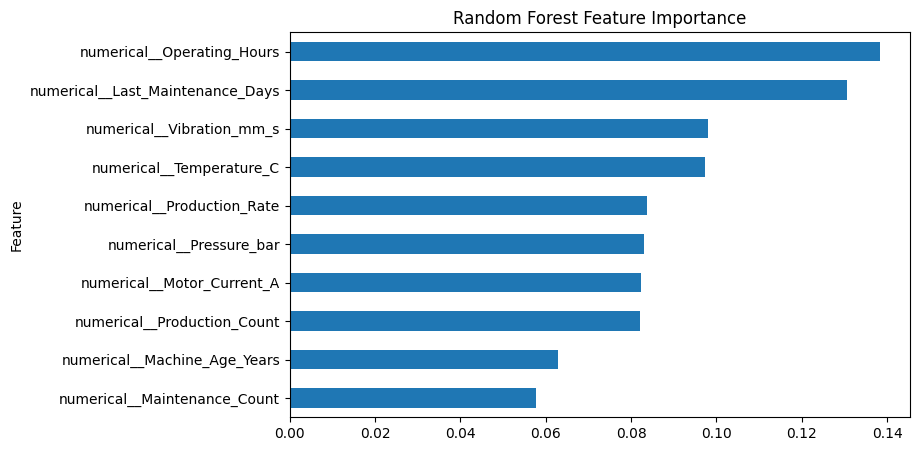

In [30]:
feature_names = (
    pipeline
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

importances = (
    pipeline
    .named_steps["model"]
    .feature_importances_
)

feature_importance = (
    pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    })
    .sort_values(
        "Importance",
        ascending=False
    )
)

feature_importance.head(15)

top_features = feature_importance.head(10)

top_features.sort_values(
    "Importance"
).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(8, 5),
    title="Random Forest Feature Importance",
    legend=False
)

plt.tight_layout()
plt.show()

Build XGBoost
Import XGBoost

In [32]:
import sys

print(sys.executable)
print(sys.version)

c:\Program Files\Python314\python.exe
3.14.3 (tags/v3.14.3:323c59a, Feb  3 2026, 16:04:56) [MSC v.1944 64 bit (AMD64)]


In [1]:
import sys

print(sys.executable)

d:\Manufacturing-AI-Decision-Copilot\venv\Scripts\python.exe


In [13]:
import pandas as pd
import numpy as np

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

from xgboost import XGBClassifier

Load the final dataset

In [14]:
data_path = Path("../data/raw/manufacturing_data.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print(df["Failure_Next_30_Days"].value_counts())

Dataset shape: (10000, 16)
Failure_Next_30_Days
0    7863
1    2137
Name: count, dtype: int64


Define features

In [15]:
features = [
    "Machine_Type",
    "Machine_Age_Years",
    "Operating_Hours",
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar",
    "Motor_Current_A",
    "Production_Count",
    "Production_Rate",
    "Last_Maintenance_Days",
    "Maintenance_Count",
    "Failure_Count"
]

target = "Failure_Next_30_Days"

X = df[features]
y = df[target]

Define categorical/numerical features

In [16]:
categorical_features = [
    "Machine_Type"
]

numerical_features = [
    "Machine_Age_Years",
    "Operating_Hours",
    "Temperature_C",
    "Vibration_mm_s",
    "Pressure_bar",
    "Motor_Current_A",
    "Production_Count",
    "Production_Rate",
    "Last_Maintenance_Days",
    "Maintenance_Count",
    "Failure_Count"
]

Create the preprocessor

In [17]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

In [18]:
print(preprocessor)

ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['Machine_Type']),
                                ('numerical', 'passthrough',
                                 ['Machine_Age_Years', 'Operating_Hours',
                                  'Temperature_C', 'Vibration_mm_s',
                                  'Pressure_bar', 'Motor_Current_A',
                                  'Production_Count', 'Production_Rate',
                                  'Last_Maintenance_Days', 'Maintenance_Count',
                                  'Failure_Count'])])


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (8000, 12)
Testing : (2000, 12)


In [23]:
from sklearn.pipeline import Pipeline

In [24]:
import xgboost

print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.4.1


import the classifier

In [25]:
from xgboost import XGBClassifier

Create the XGBoost model

In [26]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

Create the pipeline

In [27]:
xgb_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", xgb_model)
    ]
)

Train

In [28]:
xgb_pipeline.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Machine_Type','Machine_Age_Years','Operating_Hours',..., 'Last_Maintenance_Days','Maintenance_Count','Failure_Count']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default

Predict

In [29]:
xgb_pred = xgb_pipeline.predict(X_test)

xgb_probability = (
    xgb_pipeline
    .predict_proba(X_test)[:, 1]
)

Evaluate

In [30]:
print(
    classification_report(
        y_test,
        xgb_pred
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        xgb_probability
    )
)

print("Confusion Matrix:")

print(
    confusion_matrix(
        y_test,
        xgb_pred
    )
)

              precision    recall  f1-score   support

           0       0.82      0.95      0.88      1573
           1       0.53      0.22      0.31       427

    accuracy                           0.79      2000
   macro avg       0.68      0.58      0.59      2000
weighted avg       0.76      0.79      0.76      2000

ROC-AUC: 0.7163388027769548
Confusion Matrix:
[[1493   80]
 [ 335   92]]


XGBoost threshold analysis

In [31]:
xgb_thresholds = [
    0.50,
    0.40,
    0.30,
    0.25,
    0.20,
    0.15
]

for threshold in xgb_thresholds:

    predictions = (
        xgb_probability >= threshold
    ).astype(int)

    precision = precision_score(
        y_test,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        zero_division=0
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

Threshold: 0.50 | Precision: 0.535 | Recall: 0.215 | F1: 0.307
Threshold: 0.40 | Precision: 0.491 | Recall: 0.319 | F1: 0.386
Threshold: 0.30 | Precision: 0.427 | Recall: 0.433 | F1: 0.430
Threshold: 0.25 | Precision: 0.390 | Recall: 0.513 | F1: 0.443
Threshold: 0.20 | Precision: 0.361 | Recall: 0.628 | F1: 0.458
Threshold: 0.15 | Precision: 0.319 | Recall: 0.761 | F1: 0.450


Recreate the Random Forest

In [33]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", rf_model)
    ]
)

rf_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Machine_Type','Machine_Age_Years','Operating_Hours',..., 'Last_Maintenance_Days','Maintenance_Count','Failure_Count']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default

Get Random Forest predictions

In [34]:
y_pred = rf_pipeline.predict(X_test)

y_probability = (
    rf_pipeline
    .predict_proba(X_test)[:, 1]
)

Verify

In [35]:
print("Random Forest ROC-AUC:",
      roc_auc_score(y_test, y_probability))

Random Forest ROC-AUC: 0.713568845461543


Create our model comparison

In [36]:
comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost"
    ],

    "ROC_AUC": [
        roc_auc_score(y_test, y_probability),
        roc_auc_score(y_test, xgb_probability)
    ],

    "Default_Precision": [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, xgb_pred, zero_division=0)
    ],

    "Default_Recall": [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, xgb_pred, zero_division=0)
    ],

    "Default_F1": [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, xgb_pred, zero_division=0)
    ]
})

comparison

,Model,ROC_AUC,Default_Precision,Default_Recall,Default_F1
0,Random Forest,0.713569,0.486301,0.332553,0.394993
1,XGBoost,0.716339,0.534884,0.215457,0.307179


Before tuning, save our experiment results

In [37]:
experiment_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost"
    ],
    "ROC_AUC": [
        0.713569,
        0.716339
    ],
    "Default_Precision": [
        0.486301,
        0.534884
    ],
    "Default_Recall": [
        0.332553,
        0.215457
    ],
    "Default_F1": [
        0.394993,
        0.307179
    ],
    "Operating_Threshold": [
        0.20,
        0.20
    ],
    "Operating_Precision": [
        0.352,
        0.361
    ],
    "Operating_Recall": [
        0.686,
        0.628
    ],
    "Operating_F1": [
        0.465,
        0.458
    ]
})

experiment_results

,Model,ROC_AUC,Default_Precision,Default_Recall,Default_F1,Operating_Threshold,Operating_Precision,Operating_Recall,Operating_F1
0,Random Forest,0.713569,0.486301,0.332553,0.394993,0.2,0.352,0.686,0.465
1,XGBoost,0.716339,0.534884,0.215457,0.307179,0.2,0.361,0.628,0.458


In [38]:
from pathlib import Path

Path("../evaluation").mkdir(
    parents=True,
    exist_ok=True
)

experiment_results.to_csv(
    "../evaluation/model_comparison.csv",
    index=False
)

print("Saved: evaluation/model_comparison.csv")

Saved: evaluation/model_comparison.csv


Random Forest tuning

In [39]:
from sklearn.model_selection import RandomizedSearchCV

rf_tuning_model = RandomForestClassifier(
    random_state=42,
    class_weight="balanced"
)

param_grid = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}

In [40]:
rf_tuning_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", rf_tuning_model)
    ]
)

Run randomized search

In [41]:
rf_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=param_grid,
    n_iter=20,
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [42]:
rf_search.fit(
    X_train,
    y_train
)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__max_depth': [None, 5, ...], 'model__max_features': ['sqrt', 'log2'], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` c

See the best configuration

In [43]:
print("Best parameters:")
print(rf_search.best_params_)

print()

print("Best CV ROC-AUC:")
print(rf_search.best_score_)

Best parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 10}

Best CV ROC-AUC:
0.714281891347202


In [44]:
tuned_rf_probability = (
    rf_search
    .predict_proba(X_test)[:, 1]
)

In [45]:
tuned_rf_pred = (
    tuned_rf_probability >= 0.20
).astype(int)

In [46]:
print(
    classification_report(
        y_test,
        tuned_rf_pred
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        tuned_rf_probability
    )
)

print("Confusion Matrix:")

print(
    confusion_matrix(
        y_test,
        tuned_rf_pred
    )
)

              precision    recall  f1-score   support

           0       0.97      0.02      0.04      1573
           1       0.22      1.00      0.36       427

    accuracy                           0.23      2000
   macro avg       0.59      0.51      0.20      2000
weighted avg       0.81      0.23      0.11      2000

ROC-AUC: 0.7317600432354532
Confusion Matrix:
[[  30 1543]
 [   1  426]]


Find the tuned Random Forest's best threshold

In [47]:
thresholds = [
    0.50,
    0.45,
    0.40,
    0.35,
    0.30,
    0.25,
    0.20,
    0.15,
    0.10
]

for threshold in thresholds:

    predictions = (
        tuned_rf_probability >= threshold
    ).astype(int)

    precision = precision_score(
        y_test,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        zero_division=0
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

Threshold: 0.50 | Precision: 0.420 | Recall: 0.546 | F1: 0.475
Threshold: 0.45 | Precision: 0.380 | Recall: 0.630 | F1: 0.474
Threshold: 0.40 | Precision: 0.348 | Recall: 0.759 | F1: 0.477
Threshold: 0.35 | Precision: 0.290 | Recall: 0.810 | F1: 0.427
Threshold: 0.30 | Precision: 0.261 | Recall: 0.892 | F1: 0.403
Threshold: 0.25 | Precision: 0.232 | Recall: 0.953 | F1: 0.373
Threshold: 0.20 | Precision: 0.216 | Recall: 0.998 | F1: 0.356
Threshold: 0.15 | Precision: 0.213 | Recall: 1.000 | F1: 0.352
Threshold: 0.10 | Precision: 0.213 | Recall: 1.000 | F1: 0.352


In [48]:
from sklearn.model_selection import train_test_split

# First split: 80% development, 20% final test
X_dev, X_test_final, y_dev, y_test_final = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: 80% training, 20% validation
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.20,
    random_state=42,
    stratify=y_dev
)

print("Training   :", X_train_final.shape)
print("Validation :", X_val.shape)
print("Final Test :", X_test_final.shape)

Training   : (6400, 12)
Validation : (1600, 12)
Final Test : (2000, 12)


Train the tuned Random Forest

In [49]:
final_rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=2,
    min_samples_leaf=4,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42
)

In [50]:
final_rf_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", final_rf_model)
    ]
)

Train using ONLY the training data

In [51]:
final_rf_pipeline.fit(
    X_train_final,
    y_train_final
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Machine_Type','Machine_Age_Years','Operating_Hours',..., 'Last_Maintenance_Days','Maintenance_Count','Failure_Count']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default

Determine the threshold using validation data

In [52]:
val_probability = (
    final_rf_pipeline
    .predict_proba(X_val)[:, 1]
)

In [53]:
thresholds = [
    0.50,
    0.45,
    0.40,
    0.35,
    0.30,
    0.25
]

for threshold in thresholds:

    val_pred = (
        val_probability >= threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        val_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        val_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        val_pred,
        zero_division=0
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

Threshold: 0.50 | Precision: 0.414 | Recall: 0.553 | F1: 0.473
Threshold: 0.45 | Precision: 0.369 | Recall: 0.637 | F1: 0.468
Threshold: 0.40 | Precision: 0.328 | Recall: 0.734 | F1: 0.453
Threshold: 0.35 | Precision: 0.291 | Recall: 0.836 | F1: 0.431
Threshold: 0.30 | Precision: 0.264 | Recall: 0.904 | F1: 0.408
Threshold: 0.25 | Precision: 0.231 | Recall: 0.950 | F1: 0.372


Final Test

In [54]:
final_test_probability = (
    final_rf_pipeline
    .predict_proba(X_test_final)[:, 1]
)

In [55]:
FINAL_THRESHOLD = 0.50

final_test_pred = (
    final_test_probability >= FINAL_THRESHOLD
).astype(int)

In [56]:
print(
    classification_report(
        y_test_final,
        final_test_pred
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test_final,
        final_test_probability
    )
)

print("Confusion Matrix:")

print(
    confusion_matrix(
        y_test_final,
        final_test_pred
    )
)

              precision    recall  f1-score   support

           0       0.86      0.79      0.83      1573
           1       0.41      0.52      0.46       427

    accuracy                           0.74      2000
   macro avg       0.63      0.66      0.64      2000
weighted avg       0.76      0.74      0.75      2000

ROC-AUC: 0.728578426044894
Confusion Matrix:
[[1247  326]
 [ 203  224]]


Save the final model

In [57]:
import joblib
from pathlib import Path

model_dir = Path("../models")
model_dir.mkdir(
    parents=True,
    exist_ok=True
)

model_path = (
    model_dir /
    "failure_prediction_model.joblib"
)

joblib.dump(
    final_rf_pipeline,
    model_path
)

print("Model saved to:")
print(model_path)

Model saved to:
..\models\failure_prediction_model.joblib


In [58]:
import json

config = {
    "model_type": "RandomForestClassifier",
    "decision_threshold": 0.50,
    "target": "Failure_Next_30_Days",
    "roc_auc": 0.728578426044894,
    "failure_recall": 0.52,
    "failure_precision": 0.41,
    "failure_f1": 0.46
}

config_path = (
    model_dir /
    "model_config.json"
)

with open(
    config_path,
    "w"
) as f:
    json.dump(
        config,
        f,
        indent=4
    )

print("Configuration saved to:")
print(config_path)

Configuration saved to:
..\models\model_config.json


Test that the saved model works

In [59]:
loaded_model = joblib.load(
    "../models/failure_prediction_model.joblib"
)

loaded_probability = (
    loaded_model
    .predict_proba(X_test_final)[:, 1]
)

print(
    "Loaded model ROC-AUC:",
    roc_auc_score(
        y_test_final,
        loaded_probability
    )
)

Loaded model ROC-AUC: 0.728578426044894
